<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">

# Accelerating Clustering Algorithms to Achieve the Highest Performance #

## Part 2: K-Means ##

**Table of Contents**
<br>
This notebook shows how to apply the K-Means clustering algorithm. This notebook covers the below sections: 

1. [Initial Envrionment Set Up](#Initial-Envrionment-Set-Up)
2. [GPU K-Means](#GPU-K-Means)
3. [Elbow Method](#Elbow-Method)
4. [Visualizing cuML K-Means Clustering with cuML UMAP](#Visualizing-cuML-K-Means-Clustering-with-cuML-UMAP)

## Initial Envrionment Set Up

In [1]:
%load_ext cudf.pandas

In [2]:
import pandas as pd
# Sample operation
cudf_df = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})
cudf_df.info()

<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   a       3 non-null      int64
 1   b       3 non-null      int64
dtypes: int64(2)
memory usage: 48.0 bytes


In [3]:
import cupy as cp
# Sample operation
guess_ages = cp.zeros((2,3))
type(guess_ages)

cupy.ndarray

## GPU K-Means

In [4]:
%load_ext cuml.accel

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from time import time

# Parameters for synthetic data
n_samples = 1_000_000
n_features = 10
n_clusters = 5
random_state = 42
n_init = 10

print("Generating data...")
# Generate synthetic data using scikit-learn
X, _ = make_blobs(n_samples=n_samples,
                  centers=n_clusters,
                  n_features=n_features,
                  random_state=random_state)
print(f"Data shape: {X.shape}")  # Expected: (5000000, 10)

# Convert the NumPy array to a CuPy array for GPU processing
X_gpu = cp.asarray(X)

print("Starting cuML K-Means...")
start_time = time()

# Initialize cuML's KMeans (note: cuML's KMeans does not use the 'n_init' parameter like scikit-learn)
kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init = n_init)
kmeans.fit(X_gpu)
end_time = time()

# Convert the cluster centers from a CuPy array back to a NumPy array for printing (if desired)
cluster_centers = cp.asnumpy(kmeans.cluster_centers_)
inertia = kmeans.inertia_

print(f"cuML K-Means completed in {end_time - start_time:.2f} seconds.")
print("Cluster centers:")
print(cluster_centers)
print(f"Inertia: {inertia}")

[2025-08-18 04:01:46.641] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-08-18 04:01:50.795] [CUML] [info] cuML: Installed accelerator for umap.
[2025-08-18 04:01:50.807] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-08-18 04:01:50.807] [CUML] [info] cuML: Successfully initialized accelerator.
Generating data...
Data shape: (1000000, 10)
Starting cuML K-Means...
cuML K-Means completed in 2.97 seconds.
Cluster centers:
[[-9.5894612   9.40134927  6.64718852 -5.74935813 -6.36148714 -6.331823
  -3.9160434   0.49396387 -1.36043    -4.17634423]
 [ 2.23339182 -7.2089787  -4.16035086 -2.66955558 -0.88409183  5.70083872
  -6.00341806  0.28741398  1.85094367 -9.07331581]
 [ 2.14981271 -6.58671716 -8.69671077  8.98093584  9.31317312  6.1678393
  -3.90385591 -8.0472971   3.68596361 -1.1991037 ]
 [-7.5580764  -0.10016038 -9.31617614  8.18915363 -4.82576791  3.24771232
  -3.76496209  0.40293545  0.93579928 -6.30238236]
 [-2.50769721  9.01538555  4.6321872   1.9699609  -6

## Elbow Method

The **Elbow Method** is a technique used to determine the optimal number of clusters in **K-Means clustering** by plotting the **within-cluster sum of squares (WCSS)** against the number of clusters. The ideal cluster count is where the WCSS curve **bends like an "elbow"**, indicating a point where adding more clusters provides **diminishing returns** in reducing variance. 

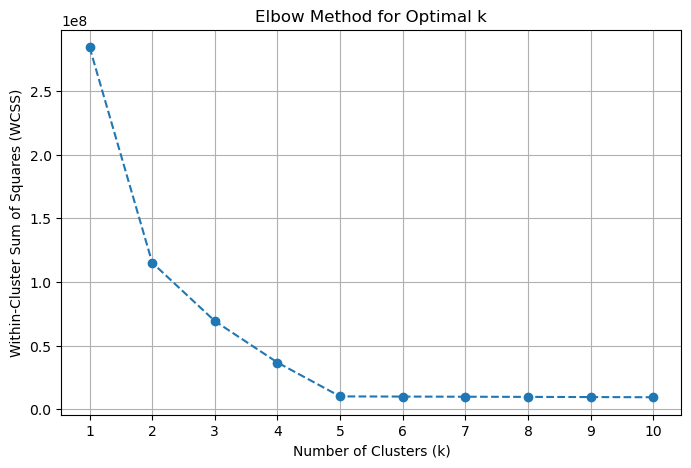

CPU times: user 1min 18s, sys: 399 ms, total: 1min 19s
Wall time: 1min 18s


In [5]:
%%time

import matplotlib.pyplot as plt

# Define range of clusters to test
cluster_range = range(1, 11)
wcss = []

# Loop through different cluster numbers
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(X_gpu)
    wcss.append(kmeans.inertia_)

# Plot WSSE vs. Number of Clusters
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal k')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

## Visualizing cuML K-Means Clustering with cuML UMAP

In [6]:
%load_ext cuml.accel

# Visualizing K-Means Clustering with UMAP
import plotly.express as px
from umap import UMAP
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Generate synthetic dataset
data, labels = make_blobs(
    n_samples=1_000_000, n_features=10, centers=5, cluster_std=1.5, random_state=42
)

# Convert data to GPU array using CuPy
data_gpu = cp.asarray(data)

# Step 1: Perform K-Means Clustering using cuML
kmeans = KMeans(n_clusters=5, random_state=42, n_init = 10)
kmeans.fit(data_gpu.get())

# Get cluster assignments
cluster_labels = kmeans.labels_

# Step 2: Reduce Dimensionality to 3D using cuML UMAP
umap_3d = UMAP(n_neighbors=15, min_dist=0.1, n_components=3)
embedding_3d = umap_3d.fit_transform(data_gpu)

# Convert GPU arrays back to NumPy for Plotly
embedding_3d_cpu = cp.asnumpy(embedding_3d)
cluster_labels_cpu = cp.asnumpy(cluster_labels)

# Step 3: Create Interactive 3D Scatter Plot using Plotly
fig = px.scatter_3d(
    x=embedding_3d_cpu[:, 0],
    y=embedding_3d_cpu[:, 1],
    z=embedding_3d_cpu[:, 2],
    color=cluster_labels_cpu.astype(str),  # Convert labels to string for coloring
    title="Interactive 3D Scatter Plot of K-Means Clusters",
    labels={"color": "Cluster"}
)

# Customize the plot
fig.update_traces(marker=dict(size=5))  # Adjust marker size
fig.update_layout(
    scene=dict(
        xaxis_title="UMAP Component 1",
        yaxis_title="UMAP Component 2",
        zaxis_title="UMAP Component 3",
    ),
    margin=dict(l=0, r=0, b=0, t=40),  # Reduce margins for a cleaner look
)

# Show the plot
fig.show()

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel
[2025-08-18 04:03:54.046] [CUML] [info] Building knn graph using nn descent


**Well Done!** Let's move to the [next notebook](03_HDBSCAN.ipynb). 

<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">